# День 1. Текст как данные: обработка сообщений технической системы

В диспетчерскую систему поступают сообщения операторов о состоянии оборудования. Нужно подготовить текстовые данные для последующего автоматического анализа. В примерах используются синтетические сообщения о насосах, датчиках, приводах, контроллерах и производственной сети. 
**Результат** преобразовать исходный текст в числовые признаки и оценить близость сообщений.

## 0. Подготовка среды

Используем `pandas`, `scikit-learn`, `matplotlib`. Для русского языка подключим `pymorphy3` как отдельный инструмент лемматизации. Если пакет недоступен, практикум продолжит работу с упрощённой нормализацией.

В Google Colab при необходимости раскомментируйте установку.

In [1]:
# В Google Colab при необходимости:
# !pip -q install pandas scikit-learn matplotlib pymorphy3

import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

try:
    import pymorphy3
    morph = pymorphy3.MorphAnalyzer()
    MORPH_AVAILABLE = True
except ImportError:
    MORPH_AVAILABLE = False

print("pymorphy3 доступен:", MORPH_AVAILABLE)

pymorphy3 доступен: True


## 1. Исходные данные и первичный осмотр

Каждая строка — короткое сообщение оператора. Сначала изучим данные как таблицу: объём, пропуски, повторяющиеся записи, распределение типов оборудования.

In [2]:
messages = [
    "Насос Н-14 перегревается после запуска, температура корпуса 82 градуса",
    "Датчик давления показывает скачки при закрытом клапане",
    "Привод конвейера остановился, на панели код ошибки E17",
    "Контроллер линии не отвечает на команды оператора",
    "После замены фильтра давление в контуре восстановилось",
    "Датчик температуры передает нестабильные значения",
    "Насос Н-08 шумит при работе на высокой нагрузке",
    "Связь с контроллером потеряна после перезапуска сети",
    "Конвейер движется рывками, требуется проверка привода",
    "Клапан не закрывается полностью, давление в системе растет",
    "Температура двигателя привода выше допустимого уровня",
    "Оператор сообщил о повторном появлении ошибки E17"
]

df = pd.DataFrame({"id": range(1, len(messages)+1), "message": messages})
display(df)
print("Количество сообщений:", len(df))
print("Пустых сообщений:", df["message"].isna().sum())
print("Дубликатов:", df["message"].duplicated().sum())

,id,message
0,1,"Насос Н-14 перегревается после запуска, темпер..."
1,2,Датчик давления показывает скачки при закрытом...
2,3,"Привод конвейера остановился, на панели код ош..."
3,4,Контроллер линии не отвечает на команды оператора
4,5,После замены фильтра давление в контуре восста...
5,6,Датчик температуры передает нестабильные значения
6,7,Насос Н-08 шумит при работе на высокой нагрузке
7,8,Связь с контроллером потеряна после перезапуск...
8,9,"Конвейер движется рывками, требуется проверка ..."
9,10,"Клапан не закрывается полностью, давление в си..."


Количество сообщений: 12
Пустых сообщений: 0
Дубликатов: 0


**Вопрос для обсуждения.** Почему до построения модели важно проверить пропуски и дубликаты? Что может произойти, если одна и та же аварийная запись попадёт в обучающую и тестовую выборки?

## 2. Токенизация

Токенизация разбивает текст на элементы — токены. В простейшем случае это слова и числовые обозначения. Для технических текстов важно не потерять коды ошибок, обозначения датчиков и номера оборудования.

In [3]:
def tokenize(text):
    # Сохраняем слова, числа и коды вида E17 или Н-14
    pattern = r"[А-Яа-яЁёA-Za-z]+(?:-[А-Яа-яЁёA-Za-z0-9]+)*|[A-Za-z]?\d+[A-Za-z0-9]*"
    return re.findall(pattern, text.lower())

sample = "Насос Н-14 перегревается, ошибка E17 после запуска!"
print(tokenize(sample))

['насос', 'н-14', 'перегревается', 'ошибка', 'e', '17', 'после', 'запуска']


### Сравнение вариантов разбиения

Словесная токенизация удобна для анализа содержания. Символьная токенизация полезна, когда важны опечатки, фрагменты кодов или морфологические окончания. Ниже сравним два представления одного сообщения.

In [4]:
text = "Датчик давления показывает скачки"
word_tokens = tokenize(text)
char_tokens = list(text.lower().replace(" ", ""))

print("Слова:", word_tokens)
print("Символы:", char_tokens)
print("Количество слов:", len(word_tokens))
print("Количество символов без пробелов:", len(char_tokens))

Слова: ['датчик', 'давления', 'показывает', 'скачки']
Символы: ['д', 'а', 'т', 'ч', 'и', 'к', 'д', 'а', 'в', 'л', 'е', 'н', 'и', 'я', 'п', 'о', 'к', 'а', 'з', 'ы', 'в', 'а', 'е', 'т', 'с', 'к', 'а', 'ч', 'к', 'и']
Количество слов: 4
Количество символов без пробелов: 30


**Мини-задание.** Измените регулярное выражение так, чтобы отдельно сохранялись десятичные значения с запятой, например `82,5`.

## 3. Нормализация, стоп-слова, лемматизация и стемминг

Нормализация приводит слова к более сопоставимому виду. Удаление стоп-слов уменьшает вклад частых служебных слов. Лемматизация приводит слово к словарной форме, а стемминг отсекает окончания и суффиксы по правилам.

Для русского языка лемматизация обычно предпочтительнее простого усечения, но требует языкового инструмента.

In [5]:
STOP_WORDS = {
    "и", "в", "на", "после", "при", "по", "для", "из", "с",
    "к", "не", "что", "это", "а", "но", "оператор"
}

def normalize_tokens(text):
    tokens = tokenize(text)
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 1]
    if MORPH_AVAILABLE:
        return [morph.parse(t)[0].normal_form for t in tokens]
    return tokens

for msg in messages[:4]:
    print(msg)
    print(" -> ", normalize_tokens(msg))

Насос Н-14 перегревается после запуска, температура корпуса 82 градуса
 ->  ['насос', 'н-14', 'перегреваться', 'запуск', 'температура', 'корпус', '82', 'градус']
Датчик давления показывает скачки при закрытом клапане
 ->  ['датчик', 'давление', 'показывать', 'скачка', 'закрытый', 'клапан']
Привод конвейера остановился, на панели код ошибки E17
 ->  ['привод', 'конвейер', 'остановиться', 'панель', 'код', 'ошибка', '17']
Контроллер линии не отвечает на команды оператора
 ->  ['контроллер', 'линия', 'отвечать', 'команда', 'оператор']


### Лемматизация и простой стемминг

Стемминг ниже намеренно упрощён: он демонстрирует идею, но не заменяет полноценный морфологический анализ.

In [6]:
def simple_stem(word):
    suffixes = ["иями", "ями", "ами", "ого", "ему", "ыми", "ими",
                "ать", "ять", "ить", "ет", "ут", "ют", "ый", "ая",
                "ое", "ые", "ов", "ам", "ах", "ом", "а", "я", "ы", "и"]
    for suffix in sorted(suffixes, key=len, reverse=True):
        if len(word) > len(suffix) + 2 and word.endswith(suffix):
            return word[:-len(suffix)]
    return word

word_forms = ["датчика", "датчики", "датчиком", "датчиков"]
print("Исходные формы:", word_forms)
print("Стемминг:", [simple_stem(w) for w in word_forms])
if MORPH_AVAILABLE:
    print("Лемматизация:", [morph.parse(w)[0].normal_form for w in word_forms])

Исходные формы: ['датчика', 'датчики', 'датчиком', 'датчиков']
Стемминг: ['датчик', 'датчик', 'датчик', 'датчик']
Лемматизация: ['датчик', 'датчик', 'датчик', 'датчик']


**Обсуждение.** Почему стемминг может объединить слова, которые имеют разный смысл? Почему технические обозначения нельзя бездумно обрабатывать как обычные слова?

## 4. Частотный анализ и облако слов

Частотный анализ показывает, какие термины чаще встречаются в массиве сообщений. Частота сама по себе не означает важность: слово «датчик» может быть частым, но мало помогать отличать один тип неисправности от другого.

,термин,частота
0,температура,3
1,давление,3
2,привод,3
3,насос,2
4,датчик,2
5,клапан,2
6,конвейер,2
7,ошибка,2
8,17,2
9,контроллер,2


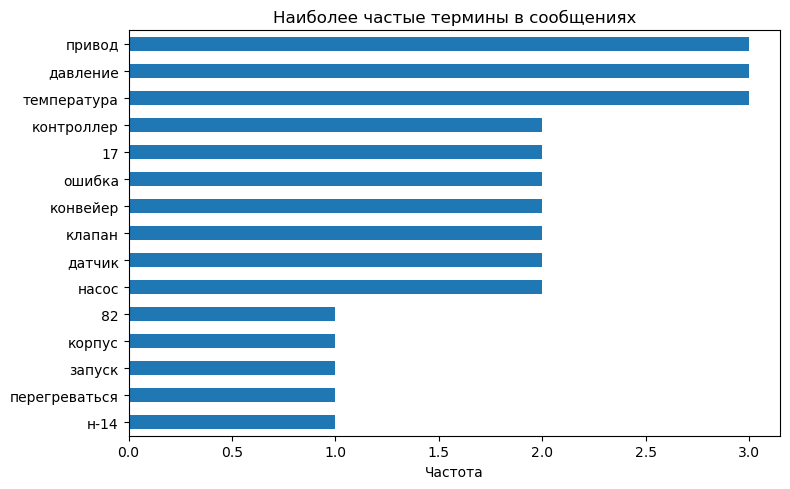

In [7]:
all_tokens = []
for msg in messages:
    all_tokens.extend(normalize_tokens(msg))

freq = Counter(all_tokens)
freq_df = pd.DataFrame(freq.most_common(15), columns=["термин", "частота"])
display(freq_df)

freq_df.sort_values("частота").plot(
    x="термин", y="частота", kind="barh", legend=False, figsize=(8, 5)
)
plt.title("Наиболее частые термины в сообщениях")
plt.xlabel("Частота")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Простая визуализация облака слов

Чтобы не зависеть от дополнительной библиотеки, покажем облако в виде набора слов, размер которых пропорционален частоте. Это не полноценный WordCloud, но хорошо иллюстрирует принцип.

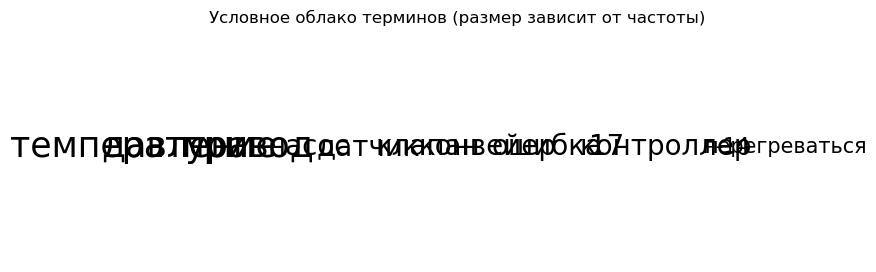

In [8]:
top = freq.most_common(12)
plt.figure(figsize=(10, 3))
for i, (word, count) in enumerate(top):
    plt.text(i, 0, word, fontsize=10 + 5*count, ha="center", va="center")
plt.xlim(-1, len(top))
plt.ylim(-1, 1)
plt.axis("off")
plt.title("Условное облако терминов (размер зависит от частоты)")
plt.show()

## 5. Векторизация: Bag of Words

Модель «мешок слов» (BoW) представляет каждый документ вектором частот словаря. Порядок слов и синтаксис не учитываются. Покажем, как из сообщений получается матрица «документы × термины».

In [9]:
from sklearn.feature_extraction.text import CountVectorizer

def tokenizer_for_vectorizer(text):
    return normalize_tokens(text)

bow = CountVectorizer(
    tokenizer=tokenizer_for_vectorizer,
    token_pattern=None,
    lowercase=False
)
X_bow = bow.fit_transform(messages)
bow_df = pd.DataFrame(
    X_bow.toarray(),
    columns=bow.get_feature_names_out(),
    index=[f"Сообщение {i}" for i in range(1, len(messages)+1)]
)
display(bow_df.iloc[:6, :12])
print("Размер матрицы BoW:", X_bow.shape)

,17,82,восстановиться,высокий,выше,градус,давление,датчик,двигатель,двигаться,допустимый,закрываться
Сообщение 1,0,1,0,0,0,1,0,0,0,0,0,0
Сообщение 2,0,0,0,0,0,0,1,1,0,0,0,0
Сообщение 3,1,0,0,0,0,0,0,0,0,0,0,0
Сообщение 4,0,0,0,0,0,0,0,0,0,0,0,0
Сообщение 5,0,0,1,0,0,0,1,0,0,0,0,0
Сообщение 6,0,0,0,0,0,0,0,1,0,0,0,0


Размер матрицы BoW: (12, 57)


**Интерпретация.** Строка матрицы — сообщение, столбец — термин. Значение показывает, сколько раз термин встретился в сообщении. Большая разреженность матрицы типична для текстовых данных.

## 6. TF-IDF: учёт информативности термина

TF-IDF повышает вес слов, характерных для конкретного документа, и снижает вес слов, часто встречающихся во всём корпусе. Поэтому редкий код ошибки может оказаться информативнее слова «система».

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    tokenizer=tokenizer_for_vectorizer,
    token_pattern=None,
    lowercase=False
)
X_tfidf = tfidf.fit_transform(messages)
tfidf_df = pd.DataFrame(
    X_tfidf.toarray(),
    columns=tfidf.get_feature_names_out(),
    index=[f"Сообщение {i}" for i in range(1, len(messages)+1)]
)
display(tfidf_df.iloc[:6, :12].round(2))
print("Размер матрицы TF-IDF:", X_tfidf.shape)

,17,82,восстановиться,высокий,выше,градус,давление,датчик,двигатель,двигаться,допустимый,закрываться
Сообщение 1,0.00,0.37,0.00,0.0,0.0,0.37,0.00,0.00,0.0,0.0,0.0,0.0
Сообщение 2,0.00,0.00,0.00,0.0,0.0,0.00,0.34,0.38,0.0,0.0,0.0,0.0
Сообщение 3,0.36,0.00,0.00,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0
Сообщение 4,0.00,0.00,0.00,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0
Сообщение 5,0.00,0.00,0.47,0.0,0.0,0.00,0.35,0.00,0.0,0.0,0.0,0.0
Сообщение 6,0.00,0.00,0.00,0.0,0.0,0.00,0.00,0.41,0.0,0.0,0.0,0.0


Размер матрицы TF-IDF: (12, 57)


In [11]:
# Для одного сообщения выведем термины с наибольшим TF-IDF-весом
row_id = 2
weights = tfidf_df.iloc[row_id].sort_values(ascending=False).head(7)
display(weights.to_frame("TF-IDF"))

,TF-IDF
панель,0.415650
код,0.415650
остановиться,0.415650
17,0.356965
ошибка,0.356965
конвейер,0.356965
привод,0.315328


**Задание.** Сравните BoW и TF-IDF для сообщений о датчиках. Как меняется вес слова, которое встречается почти во всех сообщениях?

## 7. Контекст, n-граммы и косинусное сходство

BoW и TF-IDF не понимают смысл так, как человек. Однако n-граммы позволяют учитывать короткие последовательности слов, например «потеря связи» или «скачки давления».

Косинусное сходство сравнивает направление TF-IDF-векторов.

In [12]:
bigram_vectorizer = TfidfVectorizer(
    tokenizer=tokenizer_for_vectorizer,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2)
)
X_ngram = bigram_vectorizer.fit_transform(messages)
print("Размер матрицы с биграммами:", X_ngram.shape)
print("Примеры признаков:", bigram_vectorizer.get_feature_names_out()[:25])

Размер матрицы с биграммами: (12, 114)
Примеры признаков: ['17' '82' '82 градус' 'восстановиться' 'высокий' 'высокий нагрузка'
 'выше' 'выше допустимый' 'градус' 'давление' 'давление контур'
 'давление показывать' 'давление система' 'датчик' 'датчик давление'
 'датчик температура' 'двигатель' 'двигатель привод' 'двигаться'
 'двигаться рывок' 'допустимый' 'допустимый уровень' 'закрываться'
 'закрываться полностью' 'закрытый']


In [13]:
from sklearn.metrics.pairwise import cosine_similarity

similarities = cosine_similarity(X_tfidf)
sim_df = pd.DataFrame(
    similarities.round(2),
    index=[f"M{i}" for i in range(1, len(messages)+1)],
    columns=[f"M{i}" for i in range(1, len(messages)+1)]
)
display(sim_df)

,M1,M2,M3,M4,M5,M6,M7,M8,M9,M10,M11,M12
M1,1.00,0.00,0.00,0.00,0.00,0.10,0.11,0.00,0.00,0.00,0.09,0.00
M2,0.00,1.00,0.00,0.00,0.12,0.16,0.00,0.00,0.00,0.25,0.00,0.00
M3,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.24,0.00,0.11,0.29
M4,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.16,0.00,0.00,0.00,0.00
M5,0.00,0.12,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.12,0.00,0.00
M6,0.10,0.16,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.12,0.00
M7,0.11,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
M8,0.00,0.00,0.00,0.16,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
M9,0.00,0.00,0.24,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.11,0.00
M10,0.00,0.25,0.00,0.00,0.12,0.00,0.00,0.00,0.00,1.00,0.00,0.00


In [14]:
# Найдём наиболее похожие пары разных сообщений
pairs = []
for i in range(len(messages)):
    for j in range(i+1, len(messages)):
        pairs.append((similarities[i, j], i, j))
for score, i, j in sorted(pairs, reverse=True)[:5]:
    print(f"{score:.3f} | M{i+1}: {messages[i]}")
    print(f"      | M{j+1}: {messages[j]}\n")

0.290 | M3: Привод конвейера остановился, на панели код ошибки E17
      | M12: Оператор сообщил о повторном появлении ошибки E17

0.253 | M2: Датчик давления показывает скачки при закрытом клапане
      | M10: Клапан не закрывается полностью, давление в системе растет

0.237 | M3: Привод конвейера остановился, на панели код ошибки E17
      | M9: Конвейер движется рывками, требуется проверка привода

0.158 | M2: Датчик давления показывает скачки при закрытом клапане
      | M6: Датчик температуры передает нестабильные значения

0.156 | M4: Контроллер линии не отвечает на команды оператора
      | M8: Связь с контроллером потеряна после перезапуска сети



## 8. Итоговая проверка и самостоятельная работа

1. Добавьте 5 новых сообщений о неисправностях другого оборудования.
2. Повторите токенизацию и частотный анализ.
3. Сравните BoW и TF-IDF на одном и том же корпусе.
4. Найдите два наиболее похожих сообщения.
5. Объясните, почему высокая косинусная близость не гарантирует одинаковую причину неисправности.

**Контрольный вопрос:** чем отличаются токенизация, нормализация и векторизация?